<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/deep-learning/05_pytorch_going_modular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

What is going Modular ?

* i have written me nice code in a notebook , can i resue it somewhere else

-> Ans is yes

# What is going modular?

-> Going modular involves turning notebook code (from a Jupyter Notebook or Google Colab notebook) into a series of different Python scripts that offer similar functionality.

For example, we could turn our notebook code from a series of cells into the following Python files:

* data_setup.py - a file to prepare and download data if needed.

* engine.py - a file containing various training functions.

* model_builder.py or model.py - a file to create a PyTorch model.

* train.py - a file to leverage all other files and train a target PyTorch model.

* utils.py - a file dedicated to helpful utility functions.

Why would you want to go modular?
Notebooks are fantastic for iteratively exploring and running experiments quickly.

* However, for larger scale projects you may find Python scripts more reproducible and easier to run.

* Though this is a debated topic, as companies like Netflix have shown how they use notebooks for production code.

* Production code is code that runs to offer a service to someone or something.

* For example, if you have an app running online that other people can access and use, the code running that app is considered production code.

* And libraries like fast.ai's nb-dev (short for notebook development) enable you to write whole Python libraries (including documentation) with Jupyter Notebooks.



### pros -
for notebooks
1. Easy to experiment / get started
2. easy to share (e.g link to a google colab / notebook)
3. very visual


# cons   -
for notebooks
1. versioning can be hard .
2. hard to use only specific parts .
3. text and graphics can get in the way of code.


### pros -
for python scripts

1. can package code together(saves rewriting similar code across different notebooks ).
2. can use git for versioning .
3. many open source projects use scripts
4. Larger projects can be run on cloud vendors
(not as mucb support for notebooks).

# cons =
for python scripts

1. ecperimenting isnt as visual(usually have to run the whole scipt than one cell).


## workflow

I usually start machine learning projects in Jupyter/Google Colab notebooks for quick experimentation and visualization.

Then when I've got something working, I move the most useful pieces of code to Python scripts.

here are many possible workflows for writing machine learning code. Some prefer to start with scripts, others (like me) prefer to start with notebooks and go to scripts later on.


For example, you might be instructed to run code like the following in a terminal/command line to train a model:

python train.py --model MODEL_NAME --batch_size BATCH_SIZE --lr LEARNING_RATE --num_epochs NUM_EPOCHS


Running a PyTorch train.py script on the command line with various hyperparameter settings.

-> In this case, train.py is the target Python script, it'll likely contain functions to train a PyTorch model.

-> And --model, --batch_size, --lr and --num_epochs are known as argument flags.

-> You can set these to whatever values you like and if they're compatible with train.py, they'll work, if not, they'll error.

-> For example, let's say we wanted to train our TinyVGG model from notebook 04 for 10 epochs with a batch size of 32 and a learning rate of 0.001:

-> python train.py --model tinyvgg --batch_size 32 --lr 0.001 --num_epochs 10

-> You could setup any number of these argument flags in your train.py script to suit your needs.



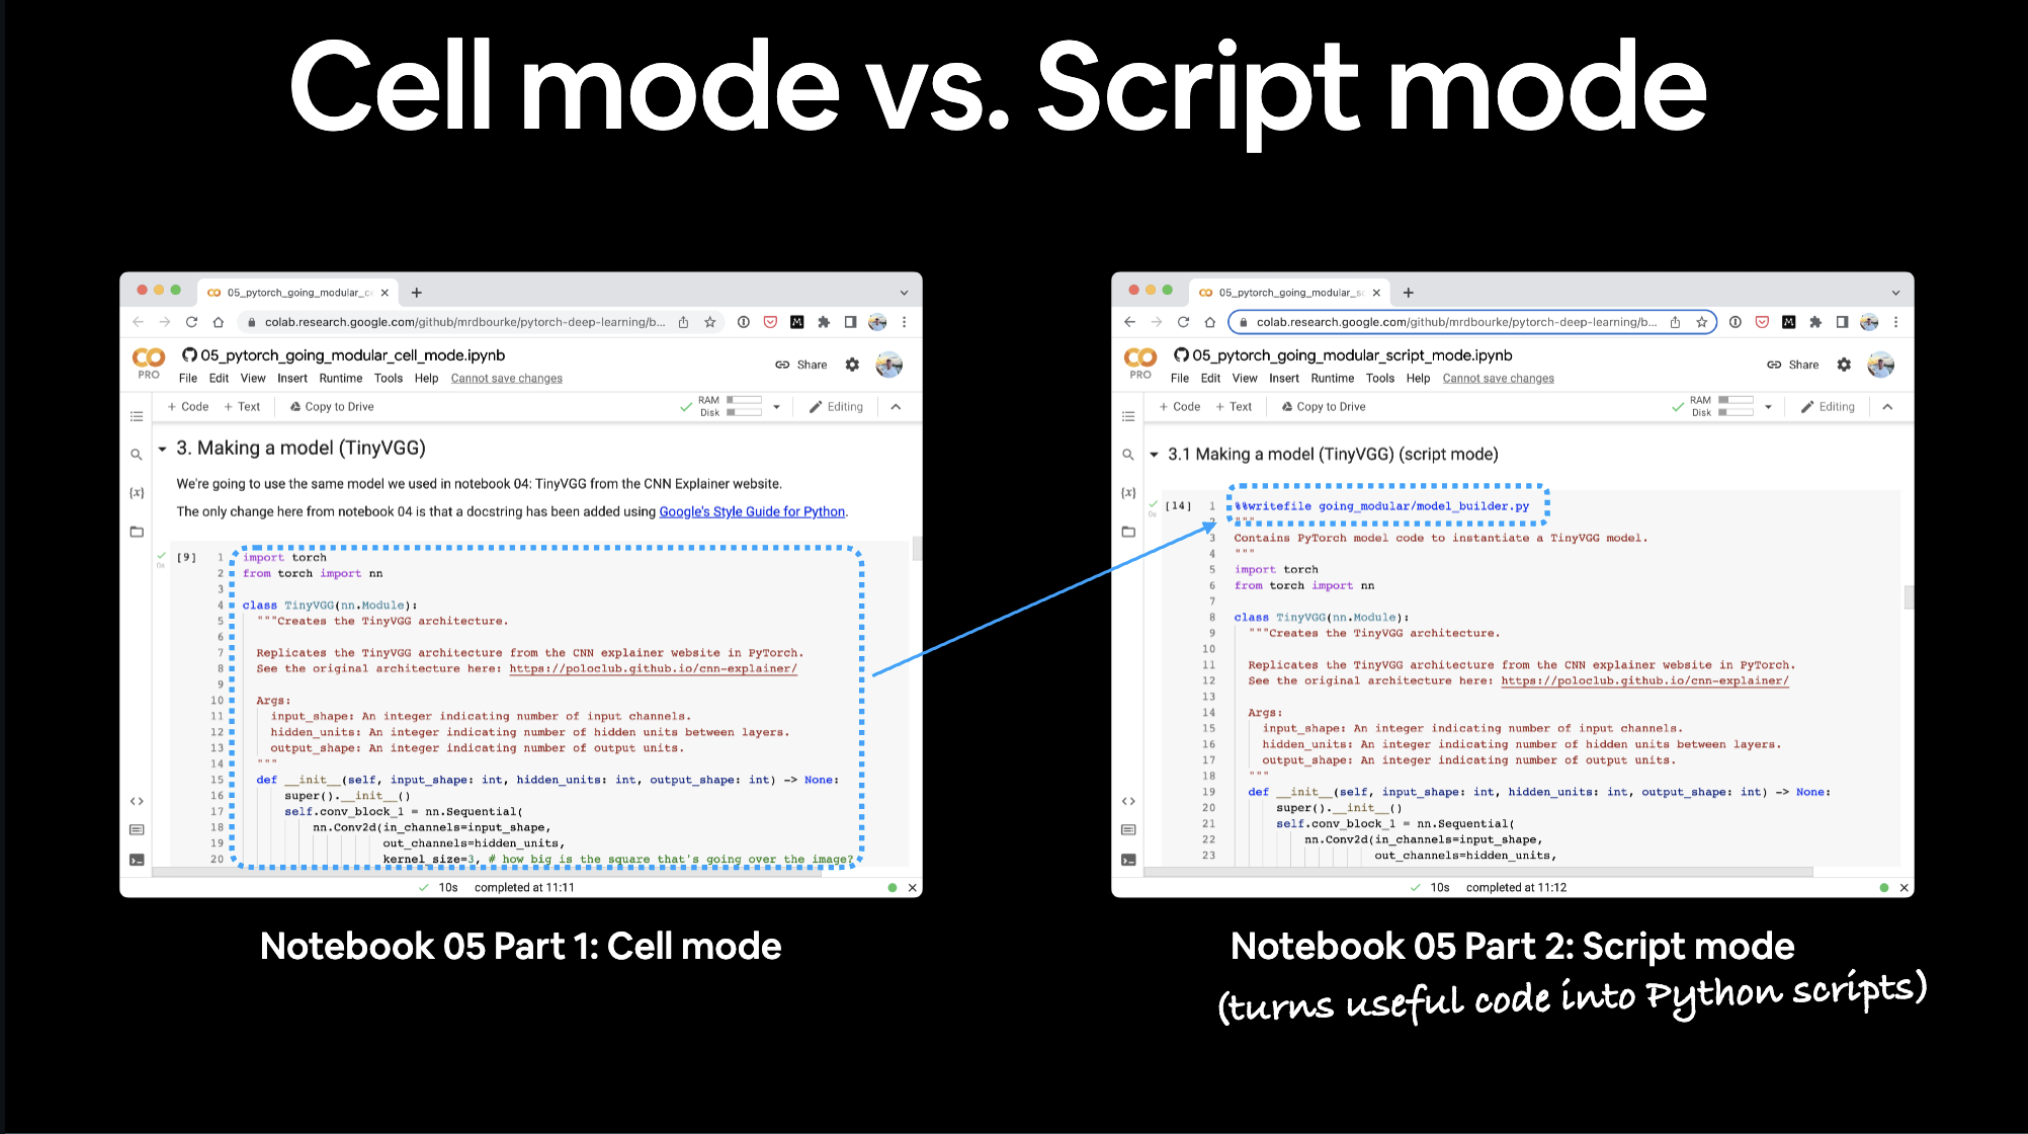

### TBR  -
* Docstrings - Writing reproducible and understandable code is important. And with this in mind, each of the functions/classes we'll be putting into scripts has been created with Google's Python docstring style in mind.

* Imports at the top of scripts - Since all of the Python scripts we're going to create could be considered a small program on their own, all of the scripts require their input modules be imported at the start of the script for example

In [1]:
import os
import torch
# import data_setup , engine , model_builder , uitls

from torchvision import transforms

# 0. Cell mode vs. script mode
A cell mode notebook such as 05. Going Modular Part 1 (cell mode) is a notebook run normally, each cell in the notebook is either code or markdown.

A script mode notebook such as 05. Going Modular Part 2 (script mode) is very similar to a cell mode notebook, however, many of the code cells may be turned into Python scripts.


# 1. Get data

Getting the data in each of the 05 notebooks happens the same as in notebook 04.

A call is made to GitHub via Python's requests module to download a .zip file and unzip it

In [2]:
import os
import requests
import zipfile
from pathlib import Path

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

if image_path.is_dir():
  print(f"{image_path} directory exists. ")
else :
  print(f"Did not find {image_path} directory , creating one...")
  image_path.mkdir(parents = True , exist_ok = True)

# download pizza ,steak , sushi data
with open(data_path / "pizza_steak_sushi.zip" , "wb") as f:
  request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
  print("Downloading pizza , steak , sushi data....")
  f.write(request.content)

# unzip pizza , steak , sushi data
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
    print("Unzipping pizza, steak, sushi data...")
    zip_ref.extractall(image_path)

# Remove zip file
os.remove(data_path / "pizza_steak_sushi.zip")

Did not find data/pizza_steak_sushi directory , creating one...
Unzipping pizza, steak, sushi data...


# 2. Create Datasets and DataLoaders (data_setup.py)
Once we've got data, we can then turn it into PyTorch Dataset's and DataLoader's (one for training data and one for testing data).

We convert the useful Dataset and DataLoader creation code into a function called create_dataloaders().

And we write it to file using the line %%writefile going_modular/data_setup.py.

In [3]:
import os
os.makedirs("going_modular", exist_ok=True)


In [4]:
%%writefile going_modular/data_setup.py

"""
contains functionality for creating Pytorch DataLoaders
for image classification data .
"""

import os
from torchvision import datasets , transforms
from torch.utils.data import DataLoader

NUM_WORKERS = os.cpu_count()

def create_dataloaders(
    train_dir : str ,
    test_dir : str ,
    transform : transforms.Compose ,
    batch_size : int,
    num_workers : int = NUM_WORKERS ):
  """
  Creates training and testing DataLoaders .

  takes in a training directory and testing directory path and turns
  them into a Pytorch Datasets and then Pytorch Dataloaders

  Args:
    train_dir: Path to training directory.
    test_dir: Path to testing directory.
    transform: torchvision transforms to perform on training and testing data.
    batch_size: Number of samples per batch in each of the DataLoaders.
    num_workers: An integer for number of workers per DataLoader.

  Returns:
    A tuple of (train_dataloader, test_dataloader, class_names).
    Where class_names is a list of the target classes.
    Example usage:
      train_dataloader, test_dataloader, class_names = \
        = create_dataloaders(train_dir=path/to/train_dir,
                            test_dir=path/to/test_dir,
                            transform=some_transform,
                            batch_size=32,
                            num_workers=4)
  """
  # use ImageFolder to create dataset
  train_data = datasets.ImageFolder(train_dir , transform = transform)
  test_data = datasets.ImageFolder(test_dir , transform = transform)

  # get class names
  class_names = train_data.classes

  # turn images into data loaders
  train_dataloader = DataLoader (
      train_data,
      batch_size = batch_size,
      shuffle = True,
      num_workers = num_workers
  )
  test_dataloader = DataLoader(
      test_data ,
      batch_size = batch_size ,
      shuffle = True,
      num_workers = num_workers,
      pin_memory = True
  )
  return train_dataloader , test_dataloader , class_names


Writing going_modular/data_setup.py


the below block in the article: is just there to show you the pattern of how you'd import and use data_setup.py — it's illustrative, not something meant to be copy-pasted and run literally with ....

In [5]:
# import data_setup.py
# from going_modular import data_setup

# create train/testt dataloader and get class_names as a list
# train_dataloader, test_dataloader ,class_names = data_setup.create_dataloaders(...)


# Making a model (model_builder.py)

lets put our TinyVGG() model class into a script with the line %%writefile going_modular/model_builder.py:

https://poloclub.github.io/cnn-explainer/

In [6]:
%%writefile going_modular/model_builder.py

"""
contains Pytorch model code to instantiate a TinyVGG model.
"""

import torch
from torch import nn

class TinyVGG(nn.Module):
  """
  creates the tinyvgg architecture

  Replicates the TinyVGG architecture from the CNN explainer website in PyTorch.
  See the original architecture here: https://poloclub.github.io/cnn-explainer/

  Args:
    input_shape: An integer indicating number of input channels.
    hidden_units: An integer indicating number of hidden units between layers.
    output_shape: An integer indicating number of output units.
  """

  def __init__(self,
               input_shape : int,
               hidden_units : int ,
               output_shape : int ):
    super().__init__()

    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels = input_shape ,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 0),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units ,
                  out_channels = hidden_units ,
                  kernel_size = 3,
                  padding = 0 ,
                  stride =1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size =2 ,
                    stride = 2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1 ,
                  padding = 0 ),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 0 ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2,
                     stride = 2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = hidden_units* 13 * 13 ,
                  out_features = output_shape)
    )

  def forward(self ,x):
    # x = self.conv_block_1(x)
    # x = self.conv_block_2(x)
    # x = self.classifier(x)
    # return x
    return self.classifier(self.conv_block_2(self.conv_block_1(x)))


Writing going_modular/model_builder.py


Now instead of coding the TinyVGG model from scratch every time, we can import it using:

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [8]:
import os
import torch
from torchvision import transforms
from going_modular import data_setup

train_dir = "data/pizza_steak_sushi/train"
test_dir = "data/pizza_steak_sushi/test"

data_transform = transforms.Compose([
    transforms.Resize(size = (64,64)),
    transforms.ToTensor()
])

train_dataloader , test_dataloader , class_names = data_setup.create_dataloaders(
    train_dir = train_dir ,
    test_dir = test_dir ,
    transform = data_transform,
    batch_size = 32
)

In [9]:
import torch
# import model_builder.py
from going_modular import model_builder

# Instantiate an instance of the model from the "model_builder.py" script
torch.manual_seed(42)
model = model_builder.TinyVGG(input_shape = 3,
                              hidden_units = 10,
                              output_shape = len(class_names)).to(device)

model

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [10]:
# model.state_dict()

# 4.  Creating train_step() and test_step() functions and train() to combine them

we wrote several training functions in notebook 04 :

1. train_step() - takes in a model , a DataLoader , a loss function and an optimizer and trains the model on the
'DataLoader' .

2. test_step() - takes in a model , a DataLoader and a loss function and evaluates the model on the DataLoader .

3. train() - performs 1. and 2. together for a given number of epochs and returns a results dictionary.

* Since these will be the engine of our model training, we can put them all into a Python script called engine.py with the line %%writefile going_modular/engine.py:

In [11]:
%%writefile going_modular/engine.py

"""
contains functions for training and testing a Pytorch model
"""
import torch
from tqdm.auto import tqdm
from typing import Dict, List , Tuple

def train_step(model : torch.nn.Module,
               dataloader : torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module ,
               optimizer : torch.optim.Optimizer ,
               device : torch.device ):
  """
  Trains a Pytorch model for a single epoch .

  Turns a target Pytorch model to training mode and then
  runs through all of the required training steps (forward
  pass , loss calculation , optimizer step ).

  Args:
    model: A PyTorch model to be trained.
    dataloader: A DataLoader instance for the model to be trained on.
    loss_fn: A PyTorch loss function to minimize.
    optimizer: A PyTorch optimizer to help minimize the loss function.
    device: A target device to compute on (e.g. "cuda" or "cpu").

  Returns:
    A tuple of training loss and training accuracy metrics.
    In the form (train_loss, train_accuracy). For example:

    (0.1112, 0.8743)

  """

  # put model in train mode
  model.train()

  # setup train loss and train accuracy values
  train_loss , train_acc = 0, 0

  # Lopp through data loader data batches
  for batches , (X,y) in enumerate(dataloader) :
    # Send data to target device
    X, y = X.to(device) , y.to(device)

    y_pred = model(X)

    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    # calculaye and accumulate accuracy metric across all batches
    y_pred_class = torch.argmax(torch.softmax(y_pred , dim = 1) , dim = 1)
    train_acc += (y_pred_class == y ).sum().item()/len(y_pred)

  # adjust metrics to get average loss and accuracy per batch
  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)
  return train_loss , train_acc

def test_step(model : torch.nn.Module,
              dataloader : torch.utils.data.DataLoader,
              loss_fn : torch.nn.Module,
              device : torch.device ):
  """Tests a PyTorch model for a single epoch.

  Turns a target PyTorch model to "eval" mode and then performs
  a forward pass on a testing dataset.

  Args:
    model: A PyTorch model to be tested.
    dataloader: A DataLoader instance for the model to be tested on.
    loss_fn: A PyTorch loss function to calculate loss on the test data.
    device: A target device to compute on (e.g. "cuda" or "cpu").

  Returns:
    A tuple of testing loss and testing accuracy metrics.
    In the form (test_loss, test_accuracy). For example:

    (0.0223, 0.8985)
  """
  # Put model in eval mode

  model.eval()

  # setup the test loss , test accuracy values
  test_loss , test_acc = 0,0

  # turn on inference context manager
  with torch.inference_mode():
    # loop through DataLoader batches
    for batch , (X,y) in enumerate (dataloader):
      # send data to target device
      X, y = X.to(device) , y.to(device)

      test_pred_logits = model(X)

      loss = loss_fn (test_pred_logits , y)
      test_loss += loss.item()

      test_pred_labels = test_pred_logits.argmax(dim = 1)
      test_acc += (test_pred_labels == y).sum().item()/len(test_pred_labels)

  # adjust metrics to get avergae loss and accuracy per batch
  test_loss = test_loss / len(dataloader)
  test_acc = test_acc / len(dataloader)
  return test_loss , test_acc


def train(model : torch.nn.Module,
          train_dataloader : torch.utils.data.DataLoader,
          test_dataloader : torch.utils.data.DataLoader,
          optimizer : torch.optim.Optimizer,
          loss_fn : torch.nn.Module,
          epochs : int ,
          device : torch.device):
  """Trains and tests a PyTorch model.

  Passes a target PyTorch models through train_step() and test_step()
  functions for a number of epochs, training and testing the model
  in the same epoch loop.

  Calculates, prints and stores evaluation metrics throughout.

  Args:
    model: A PyTorch model to be trained and tested.
    train_dataloader: A DataLoader instance for the model to be trained on.
    test_dataloader: A DataLoader instance for the model to be tested on.
    optimizer: A PyTorch optimizer to help minimize the loss function.
    loss_fn: A PyTorch loss function to calculate loss on both datasets.
    epochs: An integer indicating how many epochs to train for.
    device: A target device to compute on (e.g. "cuda" or "cpu").

  Returns:
    A dictionary of training and testing loss as well as training and
    testing accuracy metrics. Each metric has a value in a list for
    each epoch.
    In the form: {train_loss: [...],
                  train_acc: [...],
                  test_loss: [...],
                  test_acc: [...]}
    For example if training for epochs=2:
                 {train_loss: [2.0616, 1.0537],
                  train_acc: [0.3945, 0.3945],
                  test_loss: [1.2641, 1.5706],
                  test_acc: [0.3400, 0.2973]}
  """
  # Create empty results dictionary
  results = {"train_loss" : [],
             "train_acc" : [] ,
             "test_loss" : [] ,
             "test_acc" : [] }

  # loop through training and testing steps for a number or epochs
  for epoch in tqdm(range(epochs)):
    train_loss , train_acc = train_step(model = model,
                                        dataloader = train_dataloader,
                                        loss_fn = loss_fn ,
                                        optimizer = optimizer ,
                                        device = device)

    test_loss , test_acc = test_step(model = model ,
                                     dataloader = test_dataloader ,
                                     loss_fn = loss_fn,
                                     device = device)
    # print out what's happening
    print(
        f"Epochs : {epoch + 1} | "
        f"train loss : {train_loss:.4f} | "
        f"train acc : {train_acc*100:.2f}%  | "
        f"test loss : {test_loss:.4f} | "
        f"test acc : {test_acc*100:.2f}%"
     )
    # update results dictionary
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

  return results


Writing going_modular/engine.py


Now we've got the engine.py script, we can import functions from it via:



In [12]:
#import engine.py
# from going_modular import engine

# use train() by calling it from engine.py
# engine.train(...)

# 5. creating a function to save the model (utils.py)



In [13]:
%%writefile going_modular/utils.py

"""
contains various utility functions for Pytorch model training and saving .
"""

import torch
from pathlib import Path

def save_model(model : torch.nn.Module,
               target_dir : str ,
               model_name : str ):

  """Saves a Pytorch model to a target directorys

  Args:
    model: A target PyTorch model to save.
    target_dir: A directory for saving the model to.
    model_name: A filename for the saved model. Should include
    either ".pth" or ".pt" as the file extension.

  Example usage:
    save_model(model=model_0,
               target_dir="models",
               model_name="05_going_modular_tingvgg_model.pth")

  """

  # Create target directory
  target_dir_path = Path(target_dir)
  target_dir_path.mkdir(parents = True , exist_ok = True)


  # create model save path
  assert model_name.endswith(".pth") or model_name.endswith(".pt"), "model_name should end with '.pt' or '.pth' "
  model_save_path = target_dir_path / model_name

  # Save the model state dict()
  print(f"[INFO] saving model to : {model_save_path} ")
  torch.save(obj = model.state_dict(),
             f = model_save_path)


Writing going_modular/utils.py


Now if we wanted to use our save_model() function, instead of writing it all over again, we can import it and use it via:

In [14]:
# Import utils.py
#from going_modular import utils

# Save a model to file
""" save_model(model=...
           target_dir=...,
           model_name=...) """


' save_model(model=...\n           target_dir=...,\n           model_name=...) '

# 6. Train , evaluate and save the model (train.py)

* As previously discussed, you'll often come across PyTorch repositories that combine all of their functionality together in a train.py file.

* This file is essentially saying "train the model using whatever data is available".

* In our train.py file, we'll combine all of the functionality of the other Python scripts we've created and use it to train a model.

* This way we can train a PyTorch model using a single line of code on the command line:



* Note : To create train.py we'll go through the following steps:

1. Import the various dependencies, namely torch, os, torchvision.transforms and all of the scripts from the going_modular directory, data_setup, engine, model_builder, utils.

2. Note: Since train.py will be inside the going_modular directory, we can import the other modules via import ... rather than from going_modular import ....

3. Setup various hyperparameters such as batch size, number of epochs, learning rate and number of hidden units (these could be set in the future via Python's argparse).

4. Setup the training and test directories.

5. Setup device-agnostic code.

6. Create the necessary data transforms.

7. Create the DataLoaders using data_setup.py.

8. Create the model using model_builder.py.

9. Setup the loss function and optimizer.

10. Train the model using engine.py.

11. Save the model using utils.py.


And we can create the file from a notebook cell using the line %%writefile going_modular/train.py:

In [15]:
%%writefile going_modular/train.py
from torch import nn
"""
Trains a Pytorch image classsification model using device agnostic code .
"""

import os
import torch
import data_setup , engine , model_builder , utils

from torchvision import transforms

# Setup hyperparameters
NUM_EPOCHS = 10
BATCH_SIZE = 32
HIDDEN_UNITS = 10
LEARNING_RATE = 0.001

# setup directories
train_dir = "data/pizza_steak_sushi/train"
test_dir = "data/pizza_steak_sushi/test"

# setup target device
device = "cuda" if torch.cuda.is_available() else "cpu"

# create transforms
data_transform = transforms.Compose([
    transforms.Resize(size =(64, 64)),
    transforms.ToTensor()
])

# create DataLoaders with help from data_setup.py
train_dataloader ,test_dataloader,class_names = data_setup.create_dataloaders(
    train_dir = train_dir ,
    test_dir = test_dir ,
    transform = data_transform,
    batch_size = BATCH_SIZE
)

# create model wiht help from model_builder.py

model = model_builder.TinyVGG(
    input_shape = 3,
    hidden_units = HIDDEN_UNITS,
    output_shape = len(class_names)
).to(device)


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model.parameters(),
                            lr = LEARNING_RATE,
                            )


# start training wiht help from engine.py
engine.train(model = model ,
             train_dataloader = train_dataloader,
             test_dataloader = test_dataloader,
             optimizer= optimizer,
             loss_fn = loss_fn ,
             epochs = NUM_EPOCHS,
             device = device)

# save the model with help from utils.py
utils.save_model(model = model,
                 target_dir = "models",
                 model_name = "05_going_modular_script_mode_tinyvgg_model.pth")


Writing going_modular/train.py


Now we can train a PyTorch model by running the following line on the command line:

In [16]:
!python going_modular/train.py

  0% 0/10 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Epochs : 1 | train loss : 1.1019 | train acc : 28.12%  | test loss : 1.0968 | test acc : 36.27%
 10% 1/10 [00:01<00:17,  1.98s/it]Epochs : 2 | train loss : 1.0960 | train acc : 40.23%  | test loss : 1.0951 | test acc : 40.25%
 20% 2/10 [00:03<00:14,  1.82s/it]Epochs : 3 | train loss : 1.1022 | train acc : 28.12%  | test loss : 1.0965 | test acc : 38.26%
 30% 3/10 [00:06<00:14,  2.06s/it]Epochs : 4 | train loss : 1.0961 | train acc : 40.23%  | test loss : 1.0933 | test acc : 44.22%
 40% 4/10 [00:07<00:11,  1.94s/it]Epochs : 5 | train loss : 1.1024 | train acc : 28.12%  | test loss : 1.0948 | test acc : 42.23%
 50% 5/10 [00:10<00:11,  2.24s/it]Epochs : 6 | train loss : 1.1023 | train acc : 28.12%  | test loss : 1.0957 | test acc : 40.25%
 60%